### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [1]:
# Libraries for plotting (matplotlib, seaborn) and data handling (pandas, numpy)
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [2]:
# Load the coupon survey data
data = pd.read_csv('data/coupons.csv')

In [3]:
# Preview the first 5 rows
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [4]:
# Column types 
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   destination           12684 non-null  str  
 1   passanger             12684 non-null  str  
 2   weather               12684 non-null  str  
 3   temperature           12684 non-null  int64
 4   time                  12684 non-null  str  
 5   coupon                12684 non-null  str  
 6   expiration            12684 non-null  str  
 7   gender                12684 non-null  str  
 8   age                   12684 non-null  str  
 9   maritalStatus         12684 non-null  str  
 10  has_children          12684 non-null  int64
 11  education             12684 non-null  str  
 12  occupation            12684 non-null  str  
 13  income                12684 non-null  str  
 14  car                   108 non-null    str  
 15  Bar                   12577 non-null  str  
 16  CoffeeHouse    

In [5]:
# Count missing values
data.isnull().sum()

destination                 0
passanger                   0
weather                     0
temperature                 0
time                        0
coupon                      0
expiration                  0
gender                      0
age                         0
maritalStatus               0
has_children                0
education                   0
occupation                  0
income                      0
car                     12576
Bar                       107
CoffeeHouse               217
CarryAway                 151
RestaurantLessThan20      130
Restaurant20To50          189
toCoupon_GEQ5min            0
toCoupon_GEQ15min           0
toCoupon_GEQ25min           0
direction_same              0
direction_opp               0
Y                           0
dtype: int64

In [6]:
# Count duplicate rows
data.duplicated().sum()

np.int64(74)

In [7]:
# Percentage of missing values per column
data.isnull().mean() * 100

destination              0.000000
passanger                0.000000
weather                  0.000000
temperature              0.000000
time                     0.000000
coupon                   0.000000
expiration               0.000000
gender                   0.000000
age                      0.000000
maritalStatus            0.000000
has_children             0.000000
education                0.000000
occupation               0.000000
income                   0.000000
car                     99.148534
Bar                      0.843582
CoffeeHouse              1.710817
CarryAway                1.190476
RestaurantLessThan20     1.024913
Restaurant20To50         1.490066
toCoupon_GEQ5min         0.000000
toCoupon_GEQ15min        0.000000
toCoupon_GEQ25min        0.000000
direction_same           0.000000
direction_opp            0.000000
Y                        0.000000
dtype: float64

In [8]:
# duplicate rows
data[data.duplicated(keep=False)].head(10)

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
4191,Work,Alone,Sunny,80,7AM,Carry out & Take away,1d,Male,26,Single,...,never,1~3,less1,less1,1,1,1,0,1,1
4192,Work,Alone,Sunny,80,7AM,Carry out & Take away,1d,Male,26,Single,...,never,1~3,less1,less1,1,1,1,0,1,1
4235,Work,Alone,Sunny,80,7AM,Carry out & Take away,1d,Male,26,Single,...,gt8,gt8,4~8,less1,1,1,1,0,1,1
4236,Work,Alone,Sunny,80,7AM,Carry out & Take away,1d,Male,26,Single,...,gt8,gt8,4~8,less1,1,1,1,0,1,1
4279,Work,Alone,Sunny,80,7AM,Carry out & Take away,1d,Female,26,Single,...,never,4~8,1~3,less1,1,1,1,0,1,1
4280,Work,Alone,Sunny,80,7AM,Carry out & Take away,1d,Female,26,Single,...,never,4~8,1~3,less1,1,1,1,0,1,1
4323,Work,Alone,Sunny,80,7AM,Carry out & Take away,1d,Female,46,Single,...,never,4~8,1~3,1~3,1,1,1,0,1,1
4324,Work,Alone,Sunny,80,7AM,Carry out & Take away,1d,Female,46,Single,...,never,4~8,1~3,1~3,1,1,1,0,1,1
4408,Work,Alone,Sunny,80,7AM,Carry out & Take away,1d,Female,21,Single,...,never,less1,1~3,never,1,1,1,0,1,0
4409,Work,Alone,Sunny,80,7AM,Carry out & Take away,1d,Female,21,Single,...,never,less1,1~3,never,1,1,1,0,1,0


3. Decide what to do about your missing data -- drop, replace, other...

In [9]:
# Dropping the 'car' column (99% missing)
data_clean = data.drop(columns=['car'])
data_clean = data_clean.dropna()
data_clean.shape

(12079, 25)

In [10]:
# Duplicates left after dropping car column
data_clean.duplicated().sum()

np.int64(72)

In [11]:
# Removing duplicate rows
data_clean = data_clean.drop_duplicates()
data_clean.shape

(12007, 25)

### Missing data and duplicates cleanup

- **Dropped the `car` column:** about 99% of its values were missing (12,576 of 12,684), so it carries no usable information.
- **Dropped rows with missing values** in the frequency columns (`Bar`, `CoffeeHouse`, `CarryAway`, `RestaurantLessThan20`, `Restaurant20To50`). This removed 605 rows (about 4.8%). I chose to drop these rows instead of filling them in because so few were affected, and dropping them avoids making up values.
- **Removed 72 duplicate rows:** exact copies of other responses, so no response is counted twice.

**Result:** 12,007 rows and 25 columns remain, about 95% of the original data. All analysis from here on uses `data_clean`.

4. What proportion of the total observations chose to accept the coupon?



In [12]:
# Number of drivers who accepted (1) vs. rejected (0)
data_clean['Y'].value_counts()

Y
1    6825
0    5182
Name: count, dtype: int64

In [13]:
# Counts and proportions side by side
counts = data_clean['Y'].value_counts()
props = data_clean['Y'].value_counts(normalize=True)
pd.DataFrame({'count': counts, 'proportion': props.round(3)})

,count,proportion
Y,,
1,6825,0.568
0,5182,0.432


In [14]:
# Overall acceptance rate (mean of the 0/1 Y column)
print(f"Acceptance rate: {data_clean['Y'].mean():.1%}")

Acceptance rate: 56.8%


### Overall coupon acceptance

- **56.8%** of drivers accepted the coupon (6,825 of 12,007), and **43.2%** rejected it (5,182).

5. Use a bar plot to visualize the `coupon` column.

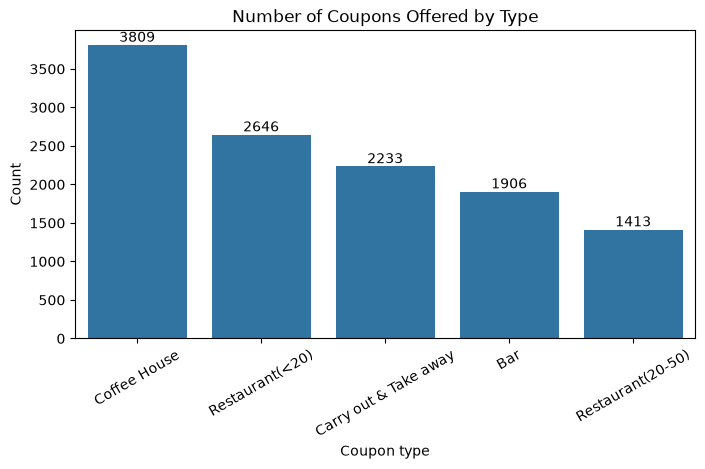

In [15]:
# Chart 1: how many times each coupon type was offered

plt.figure(figsize=(8, 4))
ax = sns.countplot(data=data_clean, x='coupon',
                   order=data_clean['coupon'].value_counts().index)
ax.bar_label(ax.containers[0])
plt.title('Number of Coupons Offered by Type')
plt.xlabel('Coupon type')
plt.ylabel('Count')
plt.xticks(rotation=30)
plt.savefig('images/coupon_counts.png', bbox_inches='tight')
plt.show()

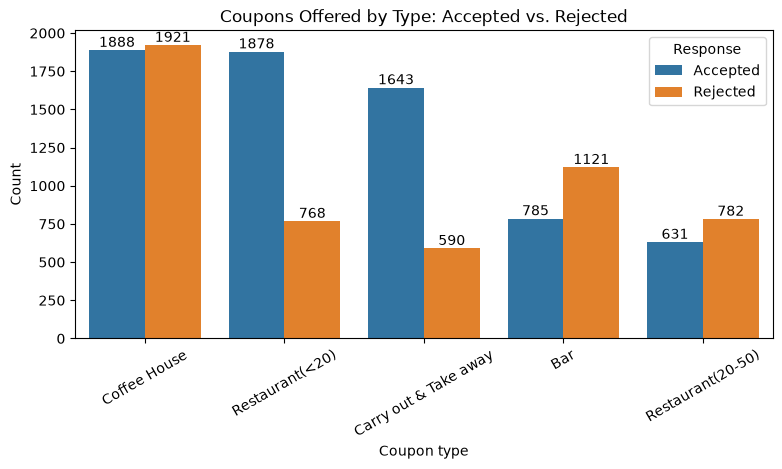

In [16]:
# Chart 2: the same counts, split by accepted vs. rejected

plot_data = data_clean.assign(Response=data_clean['Y'].map({1: 'Accepted', 0: 'Rejected'}))

plt.figure(figsize=(9, 4))
ax = sns.countplot(data=plot_data, x='coupon', hue='Response',
                   order=data_clean['coupon'].value_counts().index,
                   hue_order=['Accepted', 'Rejected'])
for container in ax.containers:
    ax.bar_label(container)
plt.title('Coupons Offered by Type: Accepted vs. Rejected')
plt.xlabel('Coupon type')
plt.ylabel('Count')
plt.xticks(rotation=30)
plt.savefig('images/coupon_counts_by_response.png', bbox_inches='tight')
plt.show()

### Coupons offered by type

- **Coffee House** coupons were offered most often (3,809, about 32% of all coupons), and **Restaurant(20-50)** coupons least often (1,413, about 12%).
- **Accepted more than rejected:** Carry out & Take away (74% accepted) and Restaurant(<20) (71%). Both are well above the overall rate of 56.8%.
- **Rejected more than accepted:** Bar (41% accepted) and Restaurant(20-50) (45%).
- **Roughly even:** Coffee House (50% accepted, 1,888 yes vs. 1,921 no).

**Takeaway:** How often a coupon was offered does not tell us how popular it is. Coffee House was the most common coupon, but only about half of drivers accepted it. Low-cost, convenient options (carry out, inexpensive restaurants) are accepted most, while bars and pricier restaurants are accepted least.

6. Use a histogram to visualize the temperature column.

In [17]:
# Temperature has only three values
data_clean['temperature'].value_counts()

temperature
80    6171
55    3652
30    2184
Name: count, dtype: int64

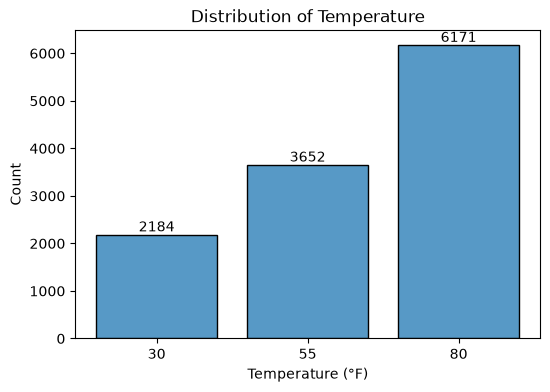

In [18]:
# Distribution of temperature in the driving scenarios
plt.figure(figsize=(6, 4))
ax = sns.histplot(data=data_clean, x='temperature',
                  bins=[17.5, 42.5, 67.5, 92.5], shrink=0.8)
ax.bar_label(ax.containers[0])
plt.title('Distribution of Temperature')
plt.xlabel('Temperature (°F)')
plt.ylabel('Count')
plt.xticks([30, 55, 80])
plt.savefig('images/temperature_distribution.png', bbox_inches='tight')
plt.show()

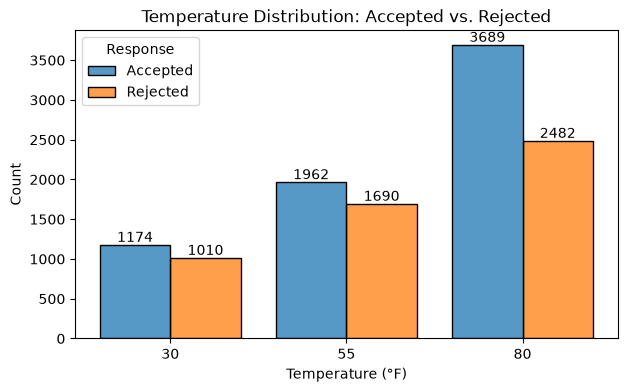

In [19]:
# Chart 2: temperature distribution, split by accepted vs. rejected
plot_data = data_clean.assign(Response=data_clean['Y'].map({1: 'Accepted', 0: 'Rejected'}))

plt.figure(figsize=(7, 4))
ax = sns.histplot(data=plot_data, x='temperature', hue='Response',
                  hue_order=['Accepted', 'Rejected'],
                  bins=[17.5, 42.5, 67.5, 92.5],
                  multiple='dodge', shrink=0.8)
for container in ax.containers:
    ax.bar_label(container)
plt.title('Temperature Distribution: Accepted vs. Rejected')
plt.xlabel('Temperature (°F)')
plt.ylabel('Count')
plt.xticks([30, 55, 80])
plt.savefig('images/temperature_by_response.png', bbox_inches='tight')
plt.show()

In [20]:
# Acceptance rate at each temperature
data_clean.groupby('temperature')['Y'].mean().round(3)

temperature
30    0.538
55    0.537
80    0.598
Name: Y, dtype: float64

### Temperature distribution

- **Temperature has only three values** in this dataset (30°F, 55°F and 80°F), so the histogram shows three bars, one per temperature.
- **80°F is the most common scenario:** 6,171 cases (about 51%), then 55°F (3,652, about 30%) and 30°F (2,184, about 18%).
- **Acceptance is higher in warm weather:** 59.8% at 80°F, compared with 53.8% at 30°F and 53.7% at 55°F. Warm weather is above the overall rate of 56.8%; cold and mild weather are below it.

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [21]:
# New DataFrame containing only the bar coupons (.copy() avoids a warning on pandas versions before 3.0)
bar_coupons = data_clean[data_clean['coupon'] == 'Bar'].copy() 
bar_coupons.shape

(1906, 25)

In [22]:
# How often bar coupon drivers go to a bar (text codes)
bar_coupons['Bar'].value_counts()

Bar
never    788
less1    546
1~3      379
4~8      147
gt8       46
Name: count, dtype: int64

2. What proportion of bar coupons were accepted?


In [23]:
# Number of bar coupons and acceptance rate for each bar-visit frequency
bar_coupons.groupby('Bar')['Y'].agg(['count', 'mean'])

,count,mean
Bar,,
1~3,379,0.646438
4~8,147,0.775510
gt8,46,0.717391
less1,546,0.446886
never,788,0.189086


In [24]:
# Proportion of bar coupons accepted - the baseline for the bar section
bar_rate = bar_coupons['Y'].mean()
print(f"Bar coupon acceptance rate: {bar_rate:.1%}")

Bar coupon acceptance rate: 41.2%


**Answer:** 41.2% of bar coupons were accepted (785 of 1,906), well below the overall acceptance rate of 56.8%.

In [25]:
#Function -  Acceptance rate and count for each group in a column
def acceptance_by(df, column):
    return (df.groupby(column)['Y']
              .agg(count='count', acceptance_rate='mean')
              .sort_values('acceptance_rate', ascending=False)
              .round(3))

# Readable names for chart titles and category labels
col_labels = {'passanger': 'Passenger', 'has_children': 'Children', 'maritalStatus': 'Marital status',
              'time': 'Time of day', 'destination': 'Destination', 'expiration': 'Expiration',
              'age': 'Age', 'gender': 'Gender', 'income': 'Income'}
freq_labels = {'never': 'Never', 'less1': 'Less than 1', '1~3': '1 to 3', '4~8': '4 to 8', 'gt8': 'More than 8'}
value_labels = {'has_children': {0: 'No children', 1: 'Has children'},
                'expiration': {'1d': '1 day', '2h': '2 hours'},
                'age': {'below21': 'Under 21', '21': '21-25', '26': '26-30', '31': '31-35',
                        '36': '36-40', '41': '41-45', '46': '46-49', '50plus': '50+'},
                # \$ escapes the dollar sign - otherwise matplotlib reads $
                'income': {'Less than $12500': r'Under \$12,500', '$12500 - $24999': r'\$12,500-24,999',
                           '$25000 - $37499': r'\$25,000-37,499', '$37500 - $49999': r'\$37,500-49,999',
                           '$50000 - $62499': r'\$50,000-62,499', '$62500 - $74999': r'\$62,500-74,999',
                           '$75000 - $87499': r'\$75,000-87,499', '$87500 - $99999': r'\$87,500-99,999',
                           '$100000 or More': r'\$100,000 or more'},
                'Bar': freq_labels, 'CoffeeHouse': freq_labels}

In [26]:
# Bar coupon acceptance by passenger type
acceptance_by(bar_coupons, 'passanger')

,count,acceptance_rate
passanger,,
Friend(s),316,0.566
Alone,1139,0.409
Partner,259,0.386
Kid(s),192,0.208


In [27]:
# Bar coupon acceptance by gender
acceptance_by(bar_coupons, 'gender')

,count,acceptance_rate
gender,,
Male,917,0.487
Female,989,0.342


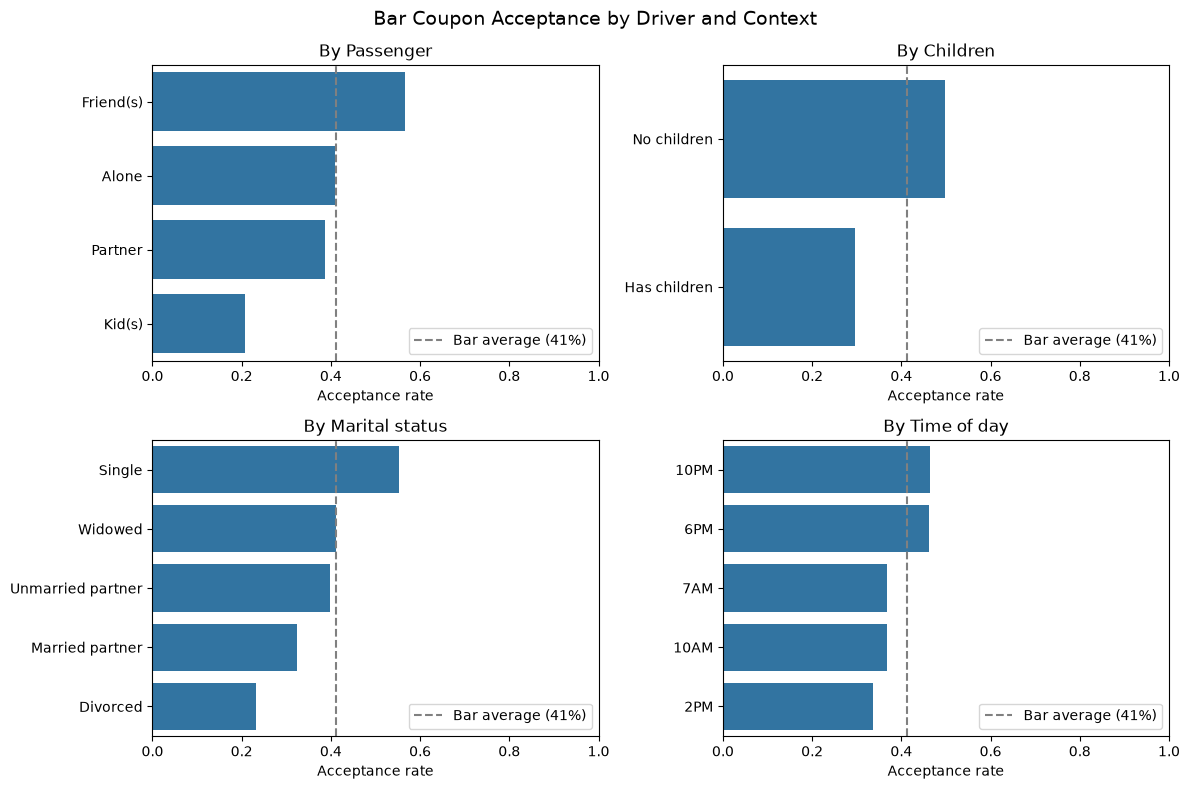

In [28]:
# Bar coupon acceptance rate by few factors - passanger, has_children, maritalStatus, time
factors = ['passanger', 'has_children', 'maritalStatus', 'time']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, factors):
    rates = acceptance_by(bar_coupons, col)
    rates = rates.rename(index=value_labels.get(col, {}))   # readable category names
    sns.barplot(x=rates['acceptance_rate'], y=rates.index.astype(str), ax=ax)
    ax.axvline(bar_rate, color='gray', linestyle='--', label=f'Bar average ({bar_rate:.0%})')
    ax.set_title(f'By {col_labels[col]}')
    ax.set_xlabel('Acceptance rate')
    ax.set_ylabel('')
    ax.set_xlim(0, 1)
    ax.legend(loc='lower right')

fig.suptitle('Bar Coupon Acceptance by Driver and Context', fontsize=14)
plt.tight_layout()
plt.savefig('images/bar_acceptance_factors.png', bbox_inches='tight')
plt.show()

In [29]:
# Acceptance rate tables behind the chart above, plus expiration
for col in ['passanger', 'has_children', 'maritalStatus', 'time', 'expiration']:
    display(acceptance_by(bar_coupons, col))

,count,acceptance_rate
passanger,,
Friend(s),316,0.566
Alone,1139,0.409
Partner,259,0.386
Kid(s),192,0.208


,count,acceptance_rate
has_children,,
0,1092,0.498
1,814,0.296


,count,acceptance_rate
maritalStatus,,
Single,638,0.553
Widowed,17,0.412
Unmarried partner,352,0.398
Married partner,826,0.324
Divorced,73,0.233


,count,acceptance_rate
time,,
10PM,379,0.464
6PM,536,0.463
7AM,462,0.368
10AM,416,0.368
2PM,113,0.336


,count,acceptance_rate
expiration,,
1d,1473,0.415
2h,433,0.400


### Who accepts bar coupons?

Compared with the bar average of 41.2%:

- **Passengers matter most:** drivers with friends accept 56.6% of bar coupons; drivers with kids only 20.8%.
- **Family situation:** drivers without children (49.8%) and single drivers (55.3%) accept far more than drivers with children (29.6%) or married drivers (32.4%).
- **Gender:** men accept bar coupons more often than women (48.7% vs. 34.2%).
- **Timing:** evening offers (6PM and 10PM, about 46%) do better than daytime offers (2PM, 33.6%).

3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


In [30]:
# True for drivers who go to a bar 3 or fewer times a month
low_freq = bar_coupons['Bar'].isin(['never', 'less1', '1~3'])

In [31]:
# Acceptance rate for each group
rate_low = bar_coupons[low_freq]['Y'].mean()
rate_high = bar_coupons[~low_freq]['Y'].mean()
print(f"3 or fewer times a month: {rate_low:.1%}  (driver count = {low_freq.sum()})")
print(f"More than 3 times a month: {rate_high:.1%}  (driver count = {(~low_freq).sum()})")

3 or fewer times a month: 37.2%  (driver count = 1713)
More than 3 times a month: 76.2%  (driver count = 193)


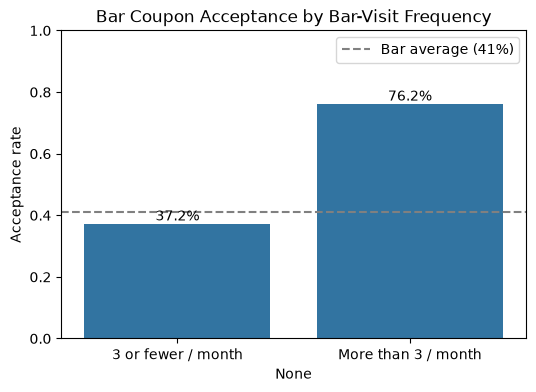

In [32]:
# Compare acceptance rates for the two groups
groups = pd.Series({'3 or fewer / month': rate_low, 'More than 3 / month': rate_high})

plt.figure(figsize=(6, 4))
ax = sns.barplot(x=groups.index, y=groups.values)
ax.bar_label(ax.containers[0], fmt='{:.1%}')
ax.axhline(bar_rate, color='gray', linestyle='--', label=f'Bar average ({bar_rate:.0%})')
plt.title('Bar Coupon Acceptance by Bar-Visit Frequency')
plt.ylabel('Acceptance rate')
plt.ylim(0, 1)
plt.legend()
plt.savefig('images/bar_q3_frequency.png', bbox_inches='tight')
plt.show()

### Bar-visit frequency: 3 or fewer times vs. more than 3 times a month

| Group | Drivers | Accepted | Acceptance rate |
|---|---|---|---|
| 3 or fewer times a month | 1,713 | 638 | 37.2% |
| More than 3 times a month | 193 | 147 | **76.2%** |

- Drivers who go to a bar **more than 3 times a month** accept bar coupons at about **twice the rate** (76.2% vs. 37.2%), a gap of about 39 percentage points.
- The frequent group is well above the bar average of 41.2%, and the less-frequent group is slightly below it.
- The less-frequent group's rate is pulled down by drivers who **never** go to bars: only 18.9% of them accepted.

4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


In [33]:
# Age codes are text, listing values
bar_coupons['age'].unique()

<ArrowStringArray>
['21', '46', '26', '31', '41', '50plus', '36', 'below21']
Length: 8, dtype: str

In [34]:
# Drivers who go to a bar more than once a month AND are over 25
over_once = bar_coupons['Bar'].isin(['1~3', '4~8', 'gt8'])
over_25 = bar_coupons['age'].isin(['26', '31', '36', '41', '46', '50plus'])

group_q4 = over_once & over_25

In [35]:
# Compare the group with all other drivers
rate_q4 = bar_coupons[group_q4]['Y'].mean()
rate_q4_others = bar_coupons[~group_q4]['Y'].mean()
print(f"Bar > once/month AND over 25: {rate_q4:.1%}  (driver count = {group_q4.sum()})")
print(f"All others:                   {rate_q4_others:.1%}  (driver count = {(~group_q4).sum()})")

Bar > once/month AND over 25: 69.0%  (driver count = 403)
All others:                   33.7%  (driver count = 1503)


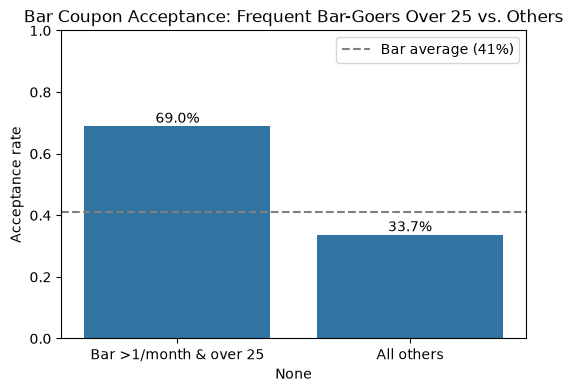

In [36]:
# Compare acceptance: bar > once/month AND over 25 vs. all others
groups_q4 = pd.Series({'Bar >1/month & over 25': rate_q4,
                       'All others': rate_q4_others})

plt.figure(figsize=(6, 4))
ax = sns.barplot(x=groups_q4.index, y=groups_q4.values)
ax.bar_label(ax.containers[0], fmt='{:.1%}')
ax.axhline(bar_rate, color='gray', linestyle='--', label=f'Bar average ({bar_rate:.0%})')
plt.title('Bar Coupon Acceptance: Frequent Bar-Goers Over 25 vs. Others')
plt.ylabel('Acceptance rate')
plt.ylim(0, 1)
plt.legend()
plt.savefig('images/bar_q4_age.png', bbox_inches='tight')
plt.show()

In [37]:
# Among drivers who go to a bar more than once a month, compare by age
age_check = pd.DataFrame({
    'Group': ['Bar >1/month, any age', 'Bar >1/month, over 25', 'Bar >1/month, 25 or under'],
    'Drivers': [over_once.sum(),
                (over_once & over_25).sum(),
                (over_once & ~over_25).sum()],
    'Acceptance rate': [bar_coupons[over_once]['Y'].mean(),
                        bar_coupons[over_once & over_25]['Y'].mean(),
                        bar_coupons[over_once & ~over_25]['Y'].mean()]
})
age_check['Acceptance rate'] = age_check['Acceptance rate'].round(3)
age_check

,Group,Drivers,Acceptance rate
0,"Bar >1/month, any age",572,0.685
1,"Bar >1/month, over 25",403,0.690
2,"Bar >1/month, 25 or under",169,0.675


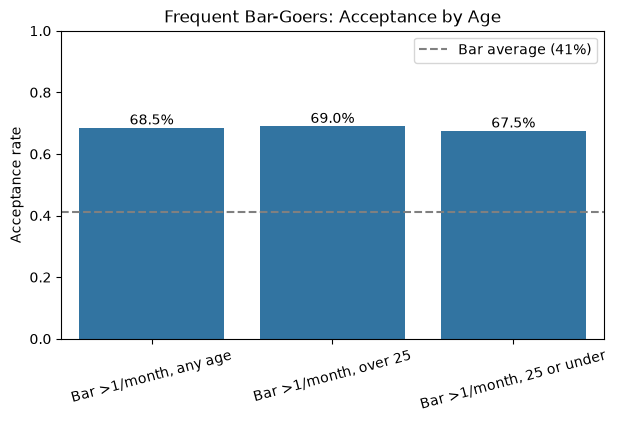

In [38]:
# age barely changes acceptance among frequent bar-goers
plt.figure(figsize=(7, 4))
ax = sns.barplot(data=age_check, x='Group', y='Acceptance rate')
ax.bar_label(ax.containers[0], fmt='{:.1%}')
ax.axhline(bar_rate, color='gray', linestyle='--', label=f'Bar average ({bar_rate:.0%})')
plt.title('Frequent Bar-Goers: Acceptance by Age')
plt.xlabel('')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend()
plt.savefig('images/bar_q4_age_check.png', bbox_inches='tight')
plt.show()

### Bar more than once a month and over 25 vs. all others

| Group | Drivers | Accepted | Acceptance rate |
|---|---|---|---|
| Bar more than once a month **and** over 25 | 403 | 278 | **69.0%** |
| All others | 1,503 | 507 | 33.7% |

- **Yes, there is a clear difference:** drivers who go to a bar more than once a month and are over 25 accept bar coupons at about **twice the rate** of all other drivers (69.0% vs. 33.7%), a gap of about 35 percentage points.
- The group is well above the bar average of 41.2%; all others are below it.

5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


In [39]:
# list occupation values
bar_coupons['occupation'].unique()

<ArrowStringArray>
[               'Architecture & Engineering',
                                   'Student',
                'Education&Training&Library',
                                'Unemployed',
                        'Healthcare Support',
      'Healthcare Practitioners & Technical',
                           'Sales & Related',
                                'Management',
  'Arts Design Entertainment Sports & Media',
                   'Computer & Mathematical',
              'Life Physical Social Science',
                   'Personal Care & Service',
           'Office & Administrative Support',
                 'Construction & Extraction',
                                     'Legal',
                                   'Retired',
               'Community & Social Services',
         'Installation Maintenance & Repair',
          'Transportation & Material Moving',
                      'Business & Financial',
                        'Protective Service',
        'Food P

In [40]:
# Passenger is not a kid
not_kid = bar_coupons['passanger'] != 'Kid(s)'

# Occupation is not farming, fishing or forestry
not_farming = bar_coupons['occupation'] != 'Farming Fishing & Forestry'

# All three conditions together
group_q5 = over_once & not_kid & not_farming

In [41]:
# Compare the group with all other drivers
rate_q5 = bar_coupons[group_q5]['Y'].mean()
rate_q5_others = bar_coupons[~group_q5]['Y'].mean()
print(f"Bar >1/month, no kids, not farming: {rate_q5:.1%}  (driver count = {group_q5.sum()})")
print(f"All others:                         {rate_q5_others:.1%}  (driver count = {(~group_q5).sum()})")

Bar >1/month, no kids, not farming: 70.9%  (driver count = 530)
All others:                         29.7%  (driver count = 1376)


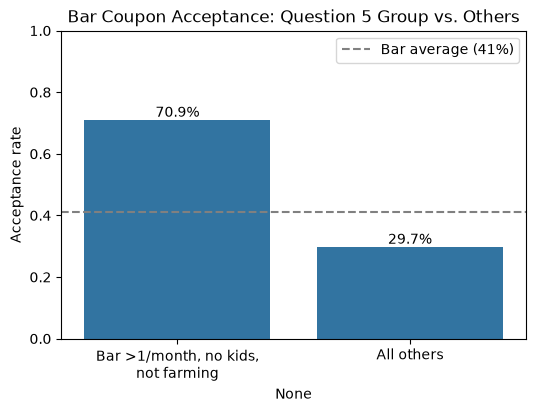

In [42]:
# Chart: acceptance for the question 5 group vs. all others
groups_q5 = pd.Series({'Bar >1/month, no kids,\nnot farming': rate_q5,
                       'All others': rate_q5_others})

plt.figure(figsize=(6, 4))
ax = sns.barplot(x=groups_q5.index, y=groups_q5.values)
ax.bar_label(ax.containers[0], fmt='{:.1%}')
ax.axhline(bar_rate, color='gray', linestyle='--', label=f'Bar average ({bar_rate:.0%})')
plt.title('Bar Coupon Acceptance: Question 5 Group vs. Others')
plt.ylabel('Acceptance rate')
plt.ylim(0, 1)
plt.legend()
plt.savefig('images/bar_q5_passenger_occupation.png', bbox_inches='tight')
plt.show()

In [43]:
# Checking what each condition adds
condition_check = pd.DataFrame({
    'Group': ['Bar >1/month (any)',
              'Bar >1/month + no kids',
              'Bar >1/month + no kids + not farming'],
    'Drivers': [over_once.sum(),
                (over_once & not_kid).sum(),
                group_q5.sum()],
    'Acceptance rate': [bar_coupons[over_once]['Y'].mean(),
                        bar_coupons[over_once & not_kid]['Y'].mean(),
                        bar_coupons[group_q5]['Y'].mean()]
})
condition_check['Acceptance rate'] = condition_check['Acceptance rate'].round(3)
condition_check

,Group,Drivers,Acceptance rate
0,Bar >1/month (any),572,0.685
1,Bar >1/month + no kids,530,0.709
2,Bar >1/month + no kids + not farming,530,0.709


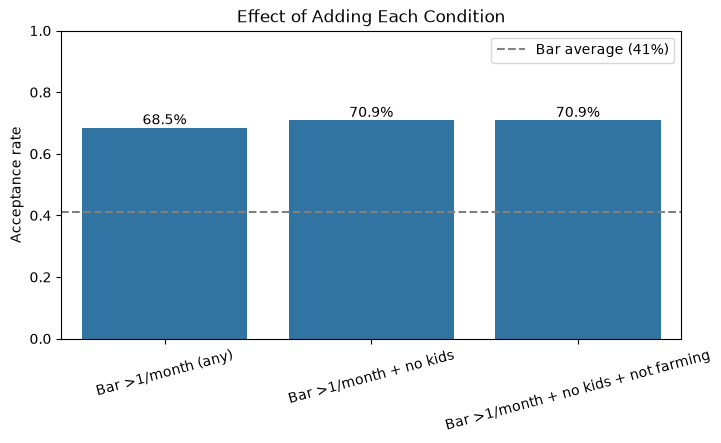

In [44]:
# how the rate changes as each condition is added
plt.figure(figsize=(8, 4))
ax = sns.barplot(data=condition_check, x='Group', y='Acceptance rate')
ax.bar_label(ax.containers[0], fmt='{:.1%}')
ax.axhline(bar_rate, color='gray', linestyle='--', label=f'Bar average ({bar_rate:.0%})')
plt.title('Effect of Adding Each Condition')
plt.xlabel('')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend()
plt.savefig('images/bar_q5_condition_check.png', bbox_inches='tight')
plt.show()

### Bar more than once a month, no kid passengers, not farming/fishing/forestry vs. all others

| Group | Drivers | Accepted | Acceptance rate |
|---|---|---|---|
| Bar more than once a month, no kids, not farming/fishing/forestry | 530 | 376 | **70.9%** |
| All others | 1,376 | 409 | 29.7% |

- **Yes, there is a large difference:** this group accepts bar coupons at more than **twice the rate** of all other drivers (70.9% vs. 29.7%), a gap of about 41 percentage points.
- The group is well above the bar average of 41.2%; all others are well below it.

6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



In [45]:
# Marital status values
bar_coupons['maritalStatus'].unique()

<ArrowStringArray>
['Single', 'Married partner', 'Unmarried partner', 'Divorced', 'Widowed']
Length: 5, dtype: str

In [46]:
# Income values
bar_coupons['income'].unique()

<ArrowStringArray>
[ '$62500 - $74999',  '$12500 - $24999',  '$75000 - $87499',
  '$50000 - $62499',  '$37500 - $49999',  '$25000 - $37499',
  '$100000 or More',  '$87500 - $99999', 'Less than $12500']
Length: 9, dtype: str

In [47]:
# Cheap restaurant (under $20) visit codes
bar_coupons['RestaurantLessThan20'].unique()

<ArrowStringArray>
['4~8', '1~3', 'less1', 'gt8', 'never']
Length: 5, dtype: str

In [48]:
# Condition A: bar >1/month, passenger not a kid, not widowed
not_widowed = bar_coupons['maritalStatus'] != 'Widowed'
cond_a = over_once & not_kid & not_widowed

# Condition B: bar >1/month, under 30
under_30 = bar_coupons['age'].isin(['below21', '21', '26'])
cond_b = over_once & under_30

# Condition C: cheap restaurants more than 4 times/month, income under 50K
cheap_rest = bar_coupons['RestaurantLessThan20'].isin(['4~8', 'gt8'])
low_income = bar_coupons['income'].isin(['Less than $12500', '$12500 - $24999',
                                         '$25000 - $37499', '$37500 - $49999'])
cond_c = cheap_rest & low_income

# Any of the three
group_q6 = cond_a | cond_b | cond_c

In [49]:
# Compare: drivers matching A, B or C vs. all others
rate_q6 = bar_coupons[group_q6]['Y'].mean()
rate_q6_others = bar_coupons[~group_q6]['Y'].mean()
print(f"Matches A, B or C: {rate_q6:.1%}  (driver count = {group_q6.sum()})")
print(f"All others:        {rate_q6_others:.1%}  (driver count = {(~group_q6).sum()})")

Matches A, B or C: 58.7%  (driver count = 746)
All others:        29.9%  (driver count = 1160)


In [50]:
# Acceptance rate for each condition on its own, combined, and for all others
q6_masks = {
    'A: bar >1/month, no kids, not widowed': cond_a,
    'B: bar >1/month, under 30': cond_b,
    'C: cheap restaurants >4/month, income <50K': cond_c,
    'A or B or C': group_q6,
    'All others': ~group_q6
}

q6_check = pd.DataFrame({
    'Group': list(q6_masks.keys()),
    'Drivers': [mask.sum() for mask in q6_masks.values()],
    'Acceptance rate': [bar_coupons[mask]['Y'].mean() for mask in q6_masks.values()]
})
q6_check['Acceptance rate'] = q6_check['Acceptance rate'].round(3)
q6_check

,Group,Drivers,Acceptance rate
0,"A: bar >1/month, no kids, not widowed",530,0.709
1,"B: bar >1/month, under 30",328,0.720
2,"C: cheap restaurants >4/month, income <50K",333,0.456
3,A or B or C,746,0.587
4,All others,1160,0.299


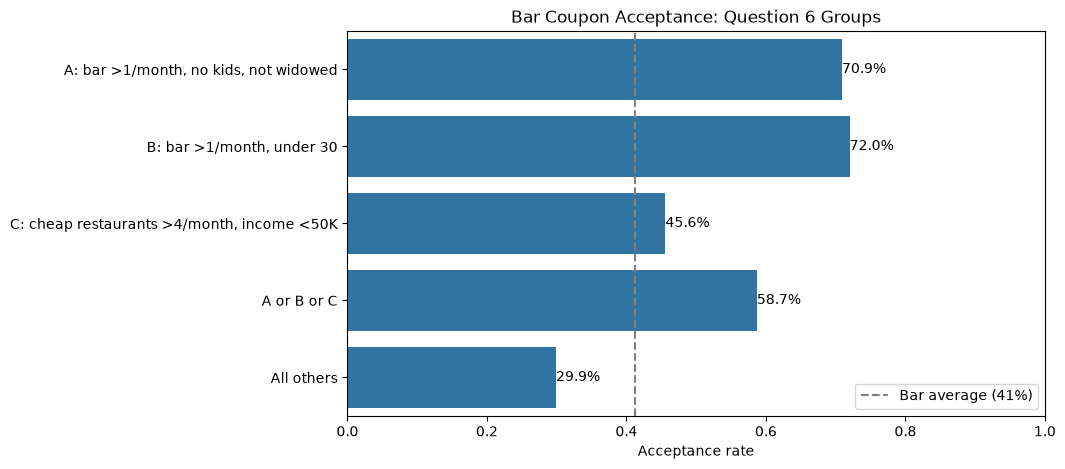

In [51]:
# Chart each condition, the combined group, and all others
plt.figure(figsize=(9, 5))
ax = sns.barplot(data=q6_check, y='Group', x='Acceptance rate')
ax.bar_label(ax.containers[0], fmt='{:.1%}')
ax.axvline(bar_rate, color='gray', linestyle='--', label=f'Bar average ({bar_rate:.0%})')
plt.title('Bar Coupon Acceptance: Question 6 Groups')
plt.ylabel('')
plt.xlim(0, 1)
plt.legend(loc='lower right')
plt.savefig('images/bar_q6_groups.png', bbox_inches='tight')
plt.show()

### Question 6: drivers matching any of three profiles vs. all others

**Profiles compared** (a driver is included if they match **any** of them):
- **A:** go to bars more than once a month, passengers not a kid, and not widowed
- **B:** go to bars more than once a month and under age 30
- **C:** go to cheap restaurants (under 20 dollars) more than 4 times a month and income under 50K

| Group | Drivers | Acceptance rate |
|---|---|---|
| A: bar >1/month, no kids, not widowed | 530 | 70.9% |
| B: bar >1/month, under 30 | 328 | **72.0%** |
| C: cheap restaurants >4/month, income <50K | 333 | 45.6% |
| **A or B or C** | **746** | **58.7%** |
| All others | 1,160 | 29.9% |

- **Yes, there is a clear difference:** drivers matching any of the three profiles accept bar coupons at about **twice the rate** of all others (58.7% vs. 29.9%).

7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

### Question 7: Hypothesis - who accepts bar coupons?

**Hypothesis:** Drivers who already go to bars regularly are the ones who accept bar coupons. The coupon works best as a reward for an existing habit - it does not create a new one.

**What the data shows:**
- **Bar visits matter most** - drivers going more than 3 times a month accept 76.2%, drivers who never go accept only 18.9%. Bar average is 41.2%.
- **Every frequent bar-goer group is high** - questions 4, 5 and 6 (profiles A and B) are all between 69% and 72%.
- **Without bar frequency the rate drops** - profile C (cheap restaurants, income under 50K) is only 45.6%.

**Other factors that help:**
- Passengers - friends 56.6% vs. kids 20.8%
- Family - single 55.3% and no children 49.8% vs. married 32.4% and with children 29.6%
- Time - evening (6PM, 10PM) about 46% vs. 2PM 33.6%
- Gender - men 48.7% vs. women 34.2%

**Factors that did not matter:**
- Age - frequent bar-goers over 25 (69.0%) and 25 or under (67.5%) are almost the same
- Occupation and widowed status - these filters did not remove any drivers
- Expiration - 1 day 41.5% vs. 2 hours 40.0%

**Likely bar coupon acceptor:** goes to bars regularly, single or no kids, out with friends in the evening.

**Limitations:**
- These are correlations, not causes. Some factors overlap (drivers with kids in the car are also often married with children).
- Some groups are small (only 46 drivers go to bars more than 8 times a month).
- This is survey data - it shows what people say they would do, not what they actually did.

### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

In [52]:
# Compare all coupon types to choose one for the independent investigation
coupon_summary = (data_clean.groupby('coupon')['Y']
                  .agg(offered='count', accepted='sum', acceptance_rate='mean')
                  .sort_values('offered', ascending=False))
coupon_summary['rejected'] = coupon_summary['offered'] - coupon_summary['accepted']
coupon_summary['acceptance_rate'] = coupon_summary['acceptance_rate'].round(3)
coupon_summary = coupon_summary[['offered', 'accepted', 'rejected', 'acceptance_rate']]
coupon_summary

,offered,accepted,rejected,acceptance_rate
coupon,,,,
Coffee House,3809,1888,1921,0.496
Restaurant(<20),2646,1878,768,0.710
Carry out & Take away,2233,1643,590,0.736
Bar,1906,785,1121,0.412
Restaurant(20-50),1413,631,782,0.447


### Choosing a coupon group for the investigation

Bar coupons were already analyzed above, so the choice is between the other four coupon types.

| Coupon | Offered | Acceptance rate | Comment |
|---|---|---|---|
| **Coffee House** | **3,809** | **49.6%** | Largest group, almost a 50/50 split |
| Restaurant(<20) | 2,646 | 71.0% | Most drivers already accept |
| Carry out & Take away | 2,233 | 73.6% | Most drivers already accept |
| Restaurant(20-50) | 1,413 | 44.7% | Smallest group |

#### Choice: Coffee House

**Reasons for choosing Coffee House:**
- **Most data** - 3,809 coupons, the largest group (about 32% of all coupons), so the acceptance rates are more reliable.
- **Most room to find differences** - acceptance is almost exactly 50/50 (1,888 accepted vs. 1,921 rejected). Carry out and cheap restaurants are already accepted by over 70% of drivers, so there is less to explain.
- **Business value** - it is the most frequently offered coupon, yet half of them are rejected. Better targeting could make a big difference.
- **Same approach as bars** - the `CoffeeHouse` column (how often a driver visits a coffee house) works like the `Bar` column, so the bar coupon method can be reused and the results compared.

### Problem statement

**Question:** What separates drivers who accept a Coffee House coupon from drivers who reject it?

- **Group** - 3,809 Coffee House coupons. 49.6% accepted, 50.4% rejected - almost an even split.
- **Approach** - compare acceptance rates across three types of factors, using the same method as the bar coupons:
  1. **Habit** - how often the driver already visits coffee houses
  2. **Situation** - time of day, destination, expiration, passengers, distance
  3. **Driver** - age, gender, income, marital status, children
- **Goal** - find the profile of drivers most likely to accept, so coffee coupons can be sent to the right drivers at the right time.

In [53]:
# Coffee House coupons only
coffee = data_clean[data_clean['coupon'] == 'Coffee House'].copy()
coffee_rate = coffee['Y'].mean()
print(f"Coffee House coupons: {len(coffee)} rows, acceptance rate {coffee_rate:.1%}")

Coffee House coupons: 3809 rows, acceptance rate 49.6%


In [54]:
# Coffee coupon acceptance by how often the driver visits a coffee house
freq_order = ['never', 'less1', '1~3', '4~8', 'gt8']
coffee_freq = acceptance_by(coffee, 'CoffeeHouse').reindex(freq_order)
coffee_freq

,count,acceptance_rate
CoffeeHouse,,
never,896,0.175
less1,1049,0.480
1~3,1015,0.647
4~8,507,0.682
gt8,342,0.658


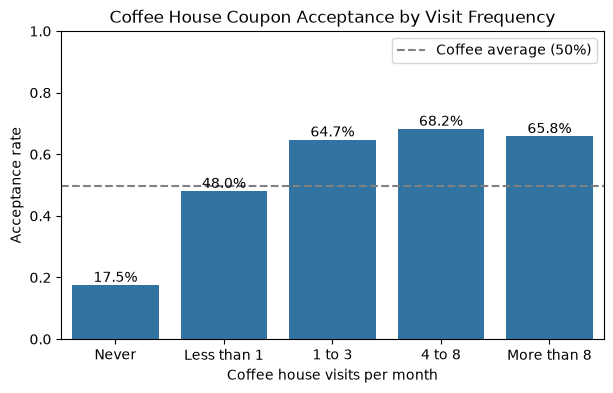

In [55]:
# Chart: acceptance rate rises with coffee house visits
plt.figure(figsize=(7, 4))
ax = sns.barplot(x=coffee_freq.rename(index=freq_labels).index, y=coffee_freq['acceptance_rate'])
ax.bar_label(ax.containers[0], fmt='{:.1%}')
ax.axhline(coffee_rate, color='gray', linestyle='--', label=f'Coffee average ({coffee_rate:.0%})')
plt.title('Coffee House Coupon Acceptance by Visit Frequency')
plt.xlabel('Coffee house visits per month')
plt.ylabel('Acceptance rate')
plt.ylim(0, 1)
plt.legend()
plt.savefig('images/coffee_frequency.png', bbox_inches='tight')
plt.show()

In [56]:
# Drivers who visit a coffee house at least once a month vs. everyone else
coffee_regular = coffee['CoffeeHouse'].isin(['1~3', '4~8', 'gt8'])

rate_regular = coffee[coffee_regular]['Y'].mean()
rate_not_regular = coffee[~coffee_regular]['Y'].mean()
print(f"Visit 1+ times a month:       {rate_regular:.1%}  (driver count = {coffee_regular.sum()})")
print(f"Less than once a month/never: {rate_not_regular:.1%}  (driver count = {(~coffee_regular).sum()})")

Visit 1+ times a month:       65.9%  (driver count = 1864)
Less than once a month/never: 33.9%  (driver count = 1945)


### Coffee House: visit frequency

**Finding:** Drivers who already go to coffee houses accept coffee coupons much more often. Coffee average is 49.6%.

| Visits per month | Drivers | Acceptance rate |
|---|---|---|
| Never | 896 | 17.5% |
| Less than once | 1,049 | 48.0% |
| 1 to 3 | 1,015 | 64.7% |
| 4 to 8 | 507 | **68.2%** |
| More than 8 | 342 | 65.8% |

**What the data shows:**
- **Regular visitors accept twice as often** - 1+ visits a month 65.9% vs. less than once or never 33.9%.
- **Never is very low** - only 17.5% accept, almost the same as bars (18.9%).
- **The rate levels off** - after 1 to 3 visits a month, more visits do not add much (64.7% to 68.2%).
- **Big audience** - regular visitors are about half of all coffee coupon drivers (1,864 of 3,809). For bars, only about 30% went more than once a month (572 of 1,906).

**Takeaway:** Same pattern as bar coupons - the coupon works best for people who already have the habit. The difference is that coffee has a much bigger group of regular customers to target.

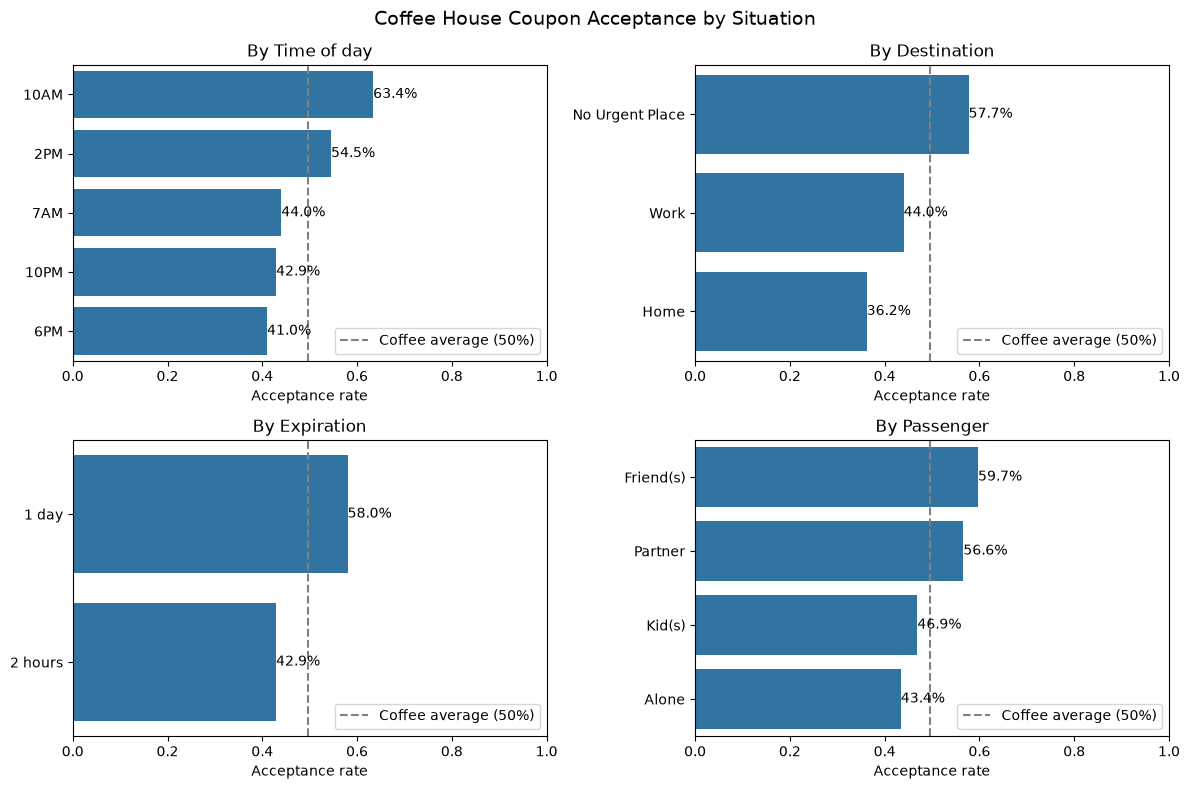

In [57]:
# Coffee coupon acceptance by situation - time, destination, expiration, passenger
coffee_factors = ['time', 'destination', 'expiration', 'passanger']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, coffee_factors):
    rates = acceptance_by(coffee, col)
    rates = rates.rename(index=value_labels.get(col, {}))   # readable category names
    sns.barplot(x=rates['acceptance_rate'], y=rates.index.astype(str), ax=ax)
    ax.bar_label(ax.containers[0], fmt='{:.1%}')
    ax.axvline(coffee_rate, color='gray', linestyle='--', label=f'Coffee average ({coffee_rate:.0%})')
    ax.set_title(f'By {col_labels[col]}')
    ax.set_xlabel('Acceptance rate')
    ax.set_ylabel('')
    ax.set_xlim(0, 1)
    ax.legend(loc='lower right')

fig.suptitle('Coffee House Coupon Acceptance by Situation', fontsize=14)
plt.tight_layout()
plt.savefig('images/coffee_situation_factors.png', bbox_inches='tight')
plt.show()

In [58]:
# Acceptance rate tables
for col in coffee_factors:
    display(acceptance_by(coffee, col))

,count,acceptance_rate
time,,
10AM,856,0.634
2PM,758,0.545
7AM,875,0.440
10PM,282,0.429
6PM,1038,0.410


,count,acceptance_rate
destination,,
No Urgent Place,2048,0.577
Work,875,0.440
Home,886,0.362


,count,acceptance_rate
expiration,,
1d,1687,0.580
2h,2122,0.429


,count,acceptance_rate
passanger,,
Friend(s),1173,0.597
Partner,290,0.566
Kid(s),192,0.469
Alone,2154,0.434


In [59]:
# Does distance to the coffee house matter?
display(acceptance_by(coffee, 'toCoupon_GEQ15min'))
display(acceptance_by(coffee, 'toCoupon_GEQ25min'))

,count,acceptance_rate
toCoupon_GEQ15min,,
0,1830,0.544
1,1979,0.451


,count,acceptance_rate
toCoupon_GEQ25min,,
0,3511,0.509
1,298,0.342


### Coffee House: time and location

**Finding:** Coffee coupons work best when the driver is relaxed and has time for a stop. Coffee average is 49.6%.

**What the data shows:**
- **Time of day** - 10AM is best at 63.4%, then 2PM 54.5%. Evening is lowest - 6PM 41.0%, 10PM 42.9%.
- **Destination** - no urgent place 57.7% vs. going home 36.2% and going to work 44.0%.
- **Expiration** - 1 day 58.0% vs. 2 hours 42.9%. A short deadline hurts.
- **Passengers** - friends 59.7% and partner 56.6% vs. alone 43.4%.
- **Distance** - under 15 minutes away 54.4%, 25+ minutes away only 34.2%.

**Different from bars:**
- **Time is reversed** - coffee peaks in the morning, bars in the evening (6PM, 10PM about 46%).
- **Expiration matters for coffee** - 15 point gap, for bars almost none (41.5% vs. 40.0%).
- **Kids hurt much less** - coffee with kids 46.9%, bars with kids only 20.8%.

**Takeaway:** Best time to send a coffee coupon - mid-morning, driver not in a hurry, coffee house close by, and give a full day to use it.

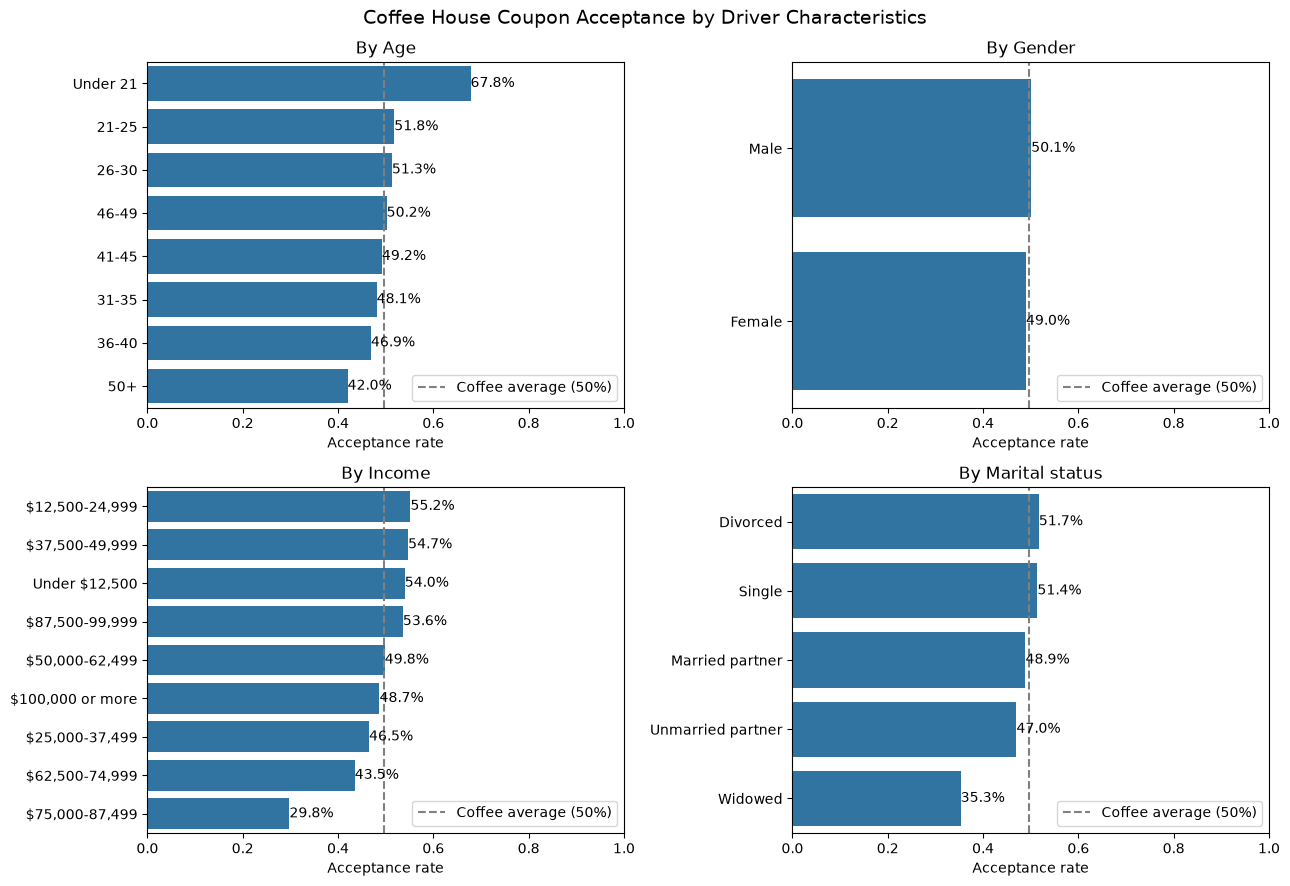

In [60]:
# Coffee coupon acceptance by driver characteristics - age, gender, income, marital status
driver_factors = ['age', 'gender', 'income', 'maritalStatus']

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.flat, driver_factors):
    rates = acceptance_by(coffee, col)
    rates = rates.rename(index=value_labels.get(col, {}))   # readable category names
    sns.barplot(x=rates['acceptance_rate'], y=rates.index.astype(str), ax=ax)
    ax.bar_label(ax.containers[0], fmt='{:.1%}')
    ax.axvline(coffee_rate, color='gray', linestyle='--', label=f'Coffee average ({coffee_rate:.0%})')
    ax.set_title(f'By {col_labels[col]}')
    ax.set_xlabel('Acceptance rate')
    ax.set_ylabel('')
    ax.set_xlim(0, 1)
    ax.legend(loc='lower right')

fig.suptitle('Coffee House Coupon Acceptance by Driver Characteristics', fontsize=14)
plt.tight_layout()
plt.savefig('images/coffee_driver_factors.png', bbox_inches='tight')
plt.show()

In [61]:
# Acceptance rate tables
for col in driver_factors + ['has_children']:
    display(acceptance_by(coffee, col))

,count,acceptance_rate
age,,
below21,143,0.678
21,844,0.518
26,797,0.513
46,213,0.502
41,317,0.492
31,584,0.481
36,382,0.469
50plus,529,0.420


,count,acceptance_rate
gender,,
Male,1843,0.501
Female,1966,0.490


,count,acceptance_rate
income,,
$12500 - $24999,565,0.552
$37500 - $49999,559,0.547
Less than $12500,298,0.540
$87500 - $99999,237,0.536
$50000 - $62499,512,0.498
$100000 or More,522,0.487
$25000 - $37499,617,0.465
$62500 - $74999,271,0.435
$75000 - $87499,228,0.298


,count,acceptance_rate
maritalStatus,,
Divorced,143,0.517
Single,1497,0.514
Married partner,1459,0.489
Unmarried partner,676,0.470
Widowed,34,0.353


,count,acceptance_rate
has_children,,
0,2357,0.501
1,1452,0.487


### Coffee House: driver profile

**Finding:** Who the driver is matters much less than the situation. Coffee average is 49.6%.

**What the data shows:**
- **Age** - the only trait with a clear effect. Under 21 is highest at 67.8% (143 drivers), 50 plus is lowest at 42.0%. Most other ages are close to average (47% to 52%).
- **Gender** - almost no difference, men 50.1% vs. women 49.0%.
- **Children** - almost no difference, no children 50.1% vs. with children 48.7%.
- **Income** - no clear pattern, rates go up and down across income levels (lowest 29.8% for \$75,000-\$87,499).
- **Marital status** - small differences, single 51.4% and divorced 51.7%. Widowed is lower at 35.3% but only 34 drivers.

**Different from bars:**
- **Gender and children matter for bars, not for coffee** - bars men 48.7% vs. women 34.2%, no children 49.8% vs. with children 29.6%.

**Takeaway:** For coffee, target by visit habit and situation (time, destination, expiration) - not by personal traits. 

In [62]:
# Combined profile: regular visitor + daytime (10AM/2PM) + 1-day expiration
coffee_daytime = coffee['time'].isin(['10AM', '2PM'])
coffee_1day = coffee['expiration'] == '1d'
best = coffee_regular & coffee_daytime & coffee_1day

print(f"Best profile:  {coffee[best]['Y'].mean():.1%}  (driver count = {best.sum()})")
print(f"Everyone else: {coffee[~best]['Y'].mean():.1%}  (driver count = {(~best).sum()})")

Best profile:  81.0%  (driver count = 358)
Everyone else: 46.3%  (driver count = 3451)


In [63]:
# Time vs. destination - all 10AM and 2PM scenarios are "No Urgent Place"
pd.crosstab(coffee['time'], coffee['destination'])

destination,Home,No Urgent Place,Work
time,,,
10AM,0,856,0
10PM,183,99,0
2PM,0,758,0
6PM,703,335,0
7AM,0,0,875


### Independent Investigation summary: who accepts Coffee House coupons?

**Answer:** Drivers who already go to coffee houses, and get the coupon when they have time for a stop. When and where the coupon is sent matters more than who the driver is. Coffee average is 49.6%.

**What the data shows:**
- **Visit habit matters most** - 1+ visits a month 65.9% vs. less than once or never 33.9%. Drivers who never go accept only 17.5%.
- **Situation matters a lot** - 10AM 63.4% vs. 6PM 41.0%, no urgent place 57.7% vs. going home 36.2%, 1 day expiration 58.0% vs. 2 hours 42.9%.
- **Distance matters** - coffee house under 15 minutes away 54.4%, 25+ minutes away only 34.2%.
- **Passengers help** - friends 59.7% and partner 56.6% vs. alone 43.4%.
- **Combined profile** - regular visitor, coupon at 10AM or 2PM, 1 day to use it - accepts 81.0% (358 drivers) vs. everyone else 46.3%.

**Factors that did not matter much:**
- Gender - men 50.1% vs. women 49.0%
- Children - no children 50.1% vs. with children 48.7%
- Income - no clear pattern

**Likely coffee coupon acceptor:** goes to coffee houses regularly, gets the coupon mid-morning, not in a hurry, coffee house nearby, and has a full day to use it.

**Coffee vs. bars:**
- **Same** - existing habit is the strongest predictor for both.
- **Different** - coffee is a morning coupon, bars an evening coupon. Expiration matters for coffee but not for bars. Kids, gender and children matter for bars but not for coffee.
- **Bigger audience** - about half of coffee coupon drivers are regular visitors, compared with about 30% for bars.

**Limitations:**
- Time and destination overlap in the survey - all 10AM and 2PM scenarios are "no urgent place", so their effects cannot be separated.
- These are correlations from survey answers, not proof of cause.

### Statistical check: 95% confidence intervals

The acceptance rates above describe this sample of drivers. A **95% confidence interval** gives the range where the true rate most likely is - like the margin of error in a poll.

- **Ranges do not overlap** - the difference is real, not chance.
- **Ranges overlap** - the difference could be chance.

Four comparisons are checked - two findings that mattered and two that did not.

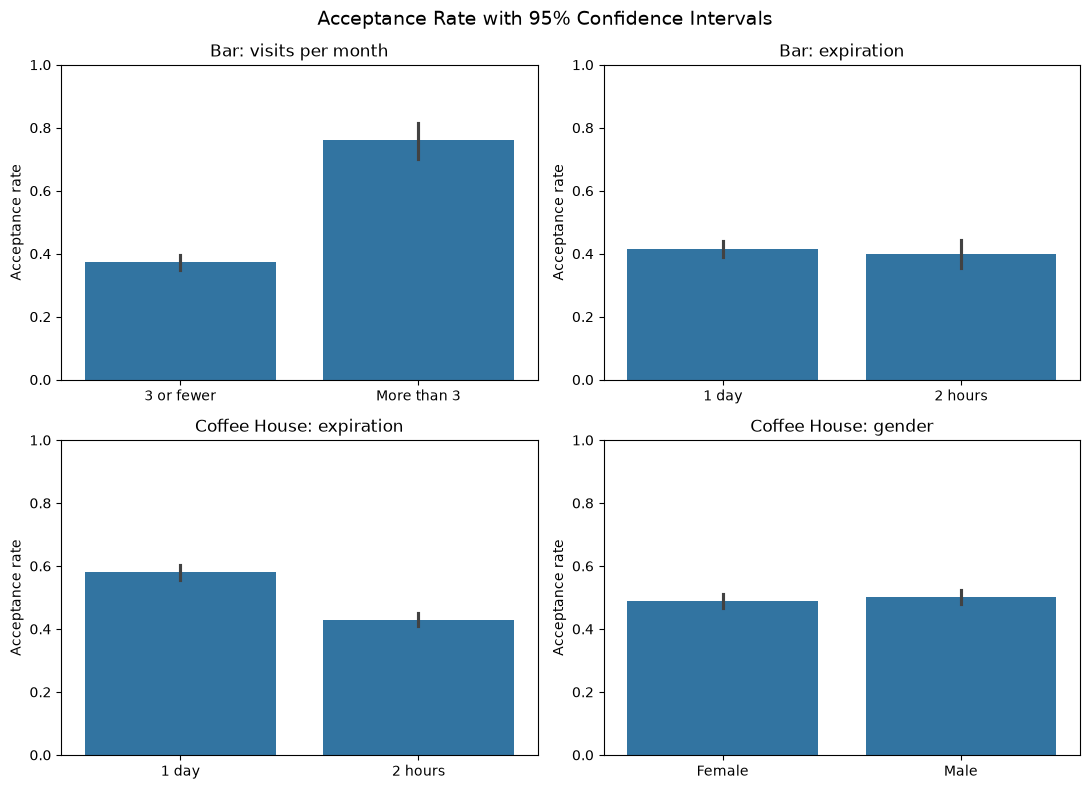

In [64]:
# Data for each comparison, with readable group names in a 'Group' column
ci_data = {
    'Bar: visits per month': bar_coupons.assign(Group=np.where(low_freq, '3 or fewer', 'More than 3')),
    'Bar: expiration': bar_coupons.assign(Group=bar_coupons['expiration'].map(value_labels['expiration'])),
    'Coffee House: expiration': coffee.assign(Group=coffee['expiration'].map(value_labels['expiration'])),
    'Coffee House: gender': coffee.assign(Group=coffee['gender'])
}

# Bar charts with 95% confidence intervals (black lines)
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (title, df) in zip(axes.flat, ci_data.items()):
    sns.barplot(data=df, x='Group', y='Y', order=sorted(df['Group'].unique()),
                errorbar=('ci', 95), seed=0, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('')
    ax.set_ylabel('Acceptance rate')
    ax.set_ylim(0, 1)

fig.suptitle('Acceptance Rate with 95% Confidence Intervals', fontsize=14)
plt.tight_layout()
plt.savefig('images/confidence_intervals.png', bbox_inches='tight')
plt.show()

In [65]:
# Acceptance rate with 95% margin of error for each group (in %)
def ci_table(df, column='Group'):
    t = df.groupby(column)['Y'].agg(count='count', rate='mean')
    t['margin'] = 1.96 * np.sqrt(t['rate'] * (1 - t['rate']) / t['count'])   # 95% margin of error
    t['low'] = t['rate'] - t['margin']
    t['high'] = t['rate'] + t['margin']
    return (t * [1, 100, 100, 100, 100]).round(1)   # keep count, show rates as percentages

for title, df in ci_data.items():
    print(title)
    display(ci_table(df))

Bar: visits per month


,count,rate,margin,low,high
Group,,,,,
3 or fewer,1713,37.2,2.3,35.0,39.5
More than 3,193,76.2,6.0,70.2,82.2


Bar: expiration


,count,rate,margin,low,high
Group,,,,,
1 day,1473,41.5,2.5,39.0,44.1
2 hours,433,40.0,4.6,35.3,44.6


Coffee House: expiration


,count,rate,margin,low,high
Group,,,,,
1 day,1687,58.0,2.4,55.6,60.3
2 hours,2122,42.9,2.1,40.8,45.0


Coffee House: gender


,count,rate,margin,low,high
Group,,,,,
Female,1966,49.0,2.2,46.8,51.2
Male,1843,50.1,2.3,47.9,52.4


**What the confidence intervals show:**
- **Bar visits - real difference** - 3 or fewer visits 37.2% (35.0% to 39.5%) vs. more than 3 visits 76.2% (70.2% to 82.2%). No overlap.
- **Coffee expiration - real difference** - 1 day 58.0% (55.6% to 60.3%) vs. 2 hours 42.9% (40.8% to 45.0%). No overlap.
- **Bar expiration - could be chance** - 1 day 41.5% vs. 2 hours 40.0%. Ranges overlap.
- **Coffee gender - could be chance** - men 50.1% vs. women 49.0%. Ranges overlap.
- **Small groups are less certain** - more than 3 bar visits is only 193 drivers, so its range is wide (about ±6%). Larger groups are about ±2%.

**Takeaway:** The main findings hold up - the differences are real, not chance. The factors that did not matter are also confirmed.

## Findings and Recommendations

**Goal:** find what separates drivers who accept a coupon from drivers who do not. Data - 12,007 survey responses after cleaning, 5 coupon types.

### Key findings

**Overall**
- 56.8% of drivers accepted the coupon - a small majority.
- Coupon type matters most - carry out (73.6%) and cheap restaurants (71.0%) are accepted most, bars (41.2%) and expensive restaurants (44.7%) least. Coffee House is in the middle (49.6%).
- Weather has a small effect - 80°F 59.8% vs. 30°F 53.8%.

**Bar coupons (41.2%)**
- Existing habit is the strongest predictor - more than 3 visits a month 76.2% vs. never 18.9%.
- Social and no family - friends in the car 56.6% vs. kids 20.8%, single 55.3% vs. married 32.4%.
- Evening works best - 6PM and 10PM about 46% vs. 2PM 33.6%.
- Age, occupation and expiration made little or no difference.

**Coffee House coupons (49.6%)**
- Existing habit is the strongest predictor - 1+ visits a month 65.9% vs. never 17.5%.
- Situation matters more than the driver - 10AM 63.4% vs. 6PM 41.0%, 1 day expiration 58.0% vs. 2 hours 42.9%, under 15 minutes away 54.4% vs. 25+ minutes 34.2%.
- Gender, children and income made little difference.
- Best profile (regular visitor, 10AM or 2PM, 1 day expiration) accepts 81.0%.

**Common pattern:** coupons work best as a reward for an existing habit, sent at the right time - not as a way to create new customers.

### Recommendations
1. **Target existing customers** - send bar and coffee coupons to drivers who already visit at least once a month. 
2. **Match the time to the place** - coffee coupons in the morning (10AM best), bar coupons in the evening (6PM, 10PM).
3. **Use 1 day expiration for coffee** - 58.0% vs. 42.9% for 2 hours, a difference confirmed by the confidence intervals.
4. **Do not send bar coupons to drivers with kids in the car** - only 20.8% accept. Drivers with friends are the best audience (56.6%).
5. **Prefer nearby locations for coffee** - acceptance drops from 54.4% (under 15 minutes) to 34.2% (25+ minutes).

### Next steps
- **Test in the real world** - this is survey data (what people say they would do). Run a small A/B test with real coupons to confirm the results.
- **Explore the other coupon types** - carry out, cheap restaurants and expensive restaurants were not analyzed in detail.